# 05b · Graph analytics on the full REES46 graph (Neo4j 5.26 + GDS)
Runs on the bulk-imported graph from `05a` (5.5M nodes, 59.9M relationships), not on a sample. Needs the `neo4j` service: `docker compose --profile graph up -d neo4j`.

Analyses: graph projection (scale and memory), PageRank (product importance), Louvain communities, enrichment of the K-Means-flagged users per community (links notebook 03a to the graph), fan-out detection, node similarity, Personalized PageRank, and a visual sub-graph. Metrics go to `ml/outputs/05b_metrics.json`.

In [1]:
import os, json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display
from neo4j import GraphDatabase

URI, USER, PWD = os.environ["NEO4J_URI"], os.environ["NEO4J_USER"], os.environ["NEO4J_PASSWORD"]
OUT, FIG = "/home/jovyan/work/ml/outputs", "/home/jovyan/work/laporan/gambar"
driver = GraphDatabase.driver(URI, auth=(USER, PWD))
metrics = {}

def q(query, **params):
    with driver.session(database="neo4j") as s:
        return s.run(query, **params).data()

def timed(label, query, **params):
    t0 = time.time(); r = q(query, **params); dt = round(time.time() - t0, 1)
    metrics.setdefault("timings_s", {})[label] = dt; print(f"{label}: {dt}s"); return r

def save(): json.dump(metrics, open(f"{OUT}/05b_metrics.json", "w"), indent=2, default=str)

## 1. The graph as loaded

In [2]:
metrics["labels"] = {r["l"]: r["n"] for r in q("MATCH (n) UNWIND labels(n) AS l RETURN l, count(*) AS n")}
metrics["rel_types"] = {r["t"]: r["n"] for r in q("MATCH ()-[r]->() RETURN type(r) AS t, count(*) AS n")}
metrics["interaction_types"] = {r["t"]: r["n"] for r in q("MATCH ()-[r:INTERACTED]->() RETURN r.type AS t, count(*) AS n")}
metrics["flagged_users"] = q("MATCH (u:User {flagged:true}) RETURN count(*) AS n")[0]["n"]
print(metrics["labels"], metrics["rel_types"], metrics["interaction_types"], metrics["flagged_users"], sep="\n"); save()

{'Brand': 4287, 'Category': 689, 'User': 5315274, 'Product': 205415}
{'INTERACTED': 59553973, 'OF_BRAND': 158233, 'IN_CATEGORY': 205415}
{'view': 56207099, 'cart': 2089996, 'purchase': 1256878}
101532


## 2. Projection into GDS memory
User and Product nodes with `INTERACTED` as an **undirected** relationship; the three interaction types of one user–product pair are merged into one weighted edge (`count` summed). The GDS estimate is taken before projecting.

In [3]:
est = q("CALL gds.graph.project.estimate(['User','Product'], {INTERACTED:{orientation:'UNDIRECTED', aggregation:'SUM', properties:'count'}}) YIELD requiredMemory, nodeCount, relationshipCount RETURN *")[0]
metrics["projection_estimate"] = est; print(est)
q("CALL gds.graph.drop('full', false)")
proj = timed("project_full", """CALL gds.graph.project('full', ['User','Product'],
    {INTERACTED:{orientation:'UNDIRECTED', aggregation:'SUM', properties:'count'}})
    YIELD nodeCount, relationshipCount, projectMillis RETURN *""")[0]
metrics["projection"] = proj; print(proj); save()

Received notification from DBMS server: <GqlStatusObject gql_status='01N03', status_description='warn: procedure field deprecated. The field `schema` of procedure gds.graph.drop() is deprecated.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "CALL gds.graph.drop('full', false)"


{'nodeCount': 5520689, 'relationshipCount': 119107946, 'requiredMemory': '[2787 MiB ... 3007 MiB]'}


project_full: 16.7s
{'nodeCount': 5520689, 'projectMillis': 16684, 'relationshipCount': 112425770}


## 3. PageRank: which products are structurally central?
Unweighted PageRank on the bipartite graph. Products reached by many users, who themselves touch many products, rank highest.

In [4]:
pr = timed("pagerank_write", "CALL gds.pageRank.write('full', {writeProperty:'pagerank', maxIterations:20, concurrency:4}) YIELD ranIterations, didConverge, nodePropertiesWritten RETURN *")[0]
metrics["pagerank"] = pr; print(pr)
top_pr = pd.DataFrame(q("""MATCH (p:Product) RETURN p.productId AS productId, p.brand AS brand, p.categoryCode AS category,
    p.lastPrice AS price, p.pagerank AS pagerank ORDER BY p.pagerank DESC LIMIT 15"""))
metrics["top_pagerank_products"] = top_pr.to_dict(orient="records"); display(top_pr); save()

pagerank_write: 20.8s
{'didConverge': False, 'nodePropertiesWritten': 5520689, 'ranIterations': 20}


,productId,brand,category,price,pagerank
0,1004856,samsung,electronics.smartphone,124.11,26292.470370
1,1004767,samsung,electronics.smartphone,235.60,23845.272875
2,1005115,apple,electronics.smartphone,912.50,21447.165571
3,1005105,apple,electronics.smartphone,1302.48,14541.532244
4,1002544,apple,electronics.smartphone,457.91,12201.364319
5,1004833,samsung,electronics.smartphone,167.03,12094.808231
6,1004870,samsung,electronics.smartphone,282.09,10777.923417
7,1004249,apple,electronics.smartphone,794.10,10692.051320
8,4804056,apple,electronics.audio.headphone,160.87,9364.198924
9,1004836,samsung,electronics.smartphone,229.59,8146.357764


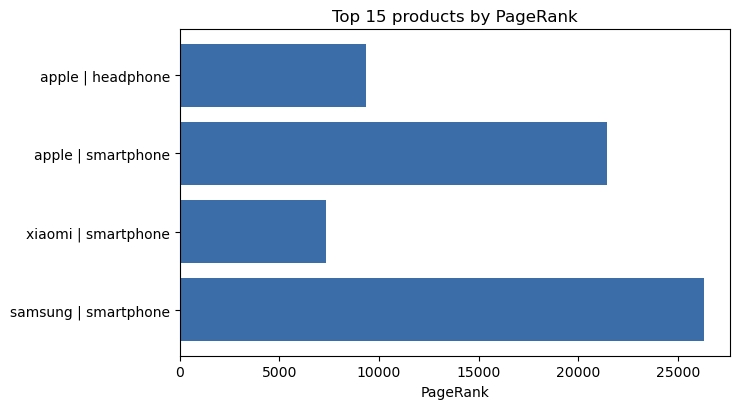

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
lab = (top_pr.brand.fillna("?") + " | " + top_pr.category.fillna("?").str.split(".").str[-1]).tolist()[::-1]
ax.barh(lab, top_pr.pagerank.tolist()[::-1], color="#3b6ea8"); ax.set_xlabel("PageRank"); ax.set_title("Top 15 products by PageRank")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_6_1_top_products_pagerank.png", dpi=160); plt.show()

## 4. Louvain community detection
Unweighted Louvain on the full projection (max 3 levels, 10 iterations per level, tolerance 1e-4) to bound runtime. Communities contain both users and products, so each community is a group of users that shop in the same part of the catalogue.

In [6]:
lv = timed("louvain_write", """CALL gds.louvain.write('full', {writeProperty:'community', maxLevels:3, maxIterations:10,
    tolerance:0.0001, concurrency:4}) YIELD communityCount, modularity, ranLevels, nodePropertiesWritten RETURN *""")[0]
metrics["louvain"] = lv; print(lv); save()

louvain_write: 44.5s
{'communityCount': 1561, 'modularity': 0.5206993416641107, 'nodePropertiesWritten': 5520689, 'ranLevels': 3}


In [7]:
comm = pd.DataFrame(q("""MATCH (u:User) WITH u.community AS community, count(*) AS users, sum(CASE WHEN u.flagged THEN 1 ELSE 0 END) AS flagged
    RETURN community, users, flagged"""))
prods = pd.DataFrame(q("MATCH (p:Product) RETURN p.community AS community, count(*) AS products")).set_index("community")
comm = comm.set_index("community").join(prods).fillna(0)
glob = comm.flagged.sum() / comm.users.sum()
comm["flag_rate"] = comm.flagged / comm.users
comm["lift"] = comm.flag_rate / glob
comm = comm.sort_values("users", ascending=False)
metrics["community_summary"] = dict(n_with_users=len(comm), global_flag_rate=glob,
    top10_users_share=float(comm.users.head(10).sum() / comm.users.sum()),
    n_ge_1000_users=int((comm.users >= 1000).sum()), largest=int(comm.users.max()))
display(comm.head(12).round(4)); print(metrics["community_summary"]); save()

,users,flagged,products,flag_rate,lift
community,,,,,
5483640,1910187,31169,7314,0.0163,0.8542
5503135,791955,15269,41148,0.0193,1.0093
5364366,698810,16146,17632,0.0231,1.2096
4917100,584569,16411,57110,0.0281,1.4697
5068921,448947,7684,20046,0.0171,0.8960
5387353,296680,6313,17881,0.0213,1.1140
5069121,292265,3750,23158,0.0128,0.6717
5016246,236745,4780,19354,0.0202,1.0570
4844625,37859,8,50,0.0002,0.0111


{'n_with_users': 1561, 'global_flag_rate': 0.019101931527894894, 'top10_users_share': 0.9974661701353496, 'n_ge_1000_users': 12, 'largest': 1910187}


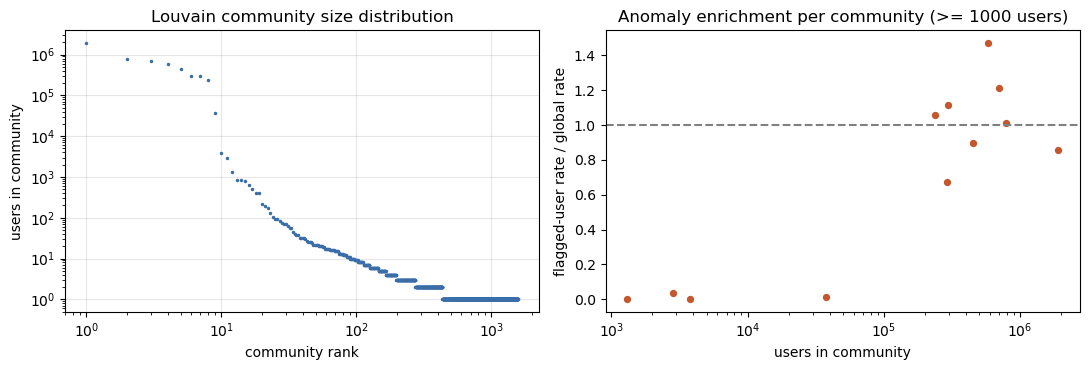

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sz = comm.users.sort_values(ascending=False).to_numpy()
ax[0].loglog(np.arange(1, len(sz) + 1), sz, ".", color="#3b6ea8", ms=3)
ax[0].set_xlabel("community rank"); ax[0].set_ylabel("users in community"); ax[0].set_title("Louvain community size distribution"); ax[0].grid(alpha=.3)
big = comm[comm.users >= 1000].sort_values("lift", ascending=False)
ax[1].scatter(big.users, big.lift, s=18, color="#c4572d")
ax[1].axhline(1, ls="--", color="gray"); ax[1].set_xscale("log")
ax[1].set_xlabel("users in community"); ax[1].set_ylabel("flagged-user rate / global rate"); ax[1].set_title("Anomaly enrichment per community (>= 1000 users)")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_6_2_communities.png", dpi=160); plt.show()
metrics["enrichment_top"] = big.head(8).reset_index().to_dict(orient="records"); save()

### What do the most enriched communities buy?
Top category branches among purchases and carts by the users of the three most flagged-enriched large communities.

In [9]:
prof = {}
for c in big.head(3).index.tolist():
    rows = q("""MATCH (u:User {community:$c})-[r:INTERACTED]->(p:Product) WHERE r.type IN ['cart','purchase'] AND p.categoryCode IS NOT NULL
        WITH split(p.categoryCode,'.')[0] AS l1, sum(r.count) AS n RETURN l1, n ORDER BY n DESC LIMIT 5""", c=int(c))
    prof[int(c)] = rows; print(c, rows)
metrics["top_enriched_community_profiles"] = prof; save()

4917100 [{'l1': 'electronics', 'n': 209971}, {'l1': 'appliances', 'n': 60965}, {'l1': 'apparel', 'n': 37619}, {'l1': 'computers', 'n': 10311}, {'l1': 'furniture', 'n': 7094}]


5364366 [{'l1': 'appliances', 'n': 365831}, {'l1': 'electronics', 'n': 268619}, {'l1': 'computers', 'n': 10997}, {'l1': 'construction', 'n': 7875}, {'l1': 'furniture', 'n': 4705}]


5387353 [{'l1': 'electronics', 'n': 87829}, {'l1': 'appliances', 'n': 35252}, {'l1': 'furniture', 'n': 31174}, {'l1': 'computers', 'n': 6141}, {'l1': 'construction', 'n': 2788}]


## 5. Fan-out detection
Users who touch more than 300 distinct products: a graph-native bot/scraper signal that does not depend on the K-Means features. Compared with the K-Means flag.

In [10]:
fan = timed("fanout", """MATCH (u:User)-[:INTERACTED]->(p:Product) WITH u, count(DISTINCT p) AS deg WHERE deg > 300
    RETURN count(*) AS fan_out_users, sum(CASE WHEN u.flagged THEN 1 ELSE 0 END) AS also_flagged, max(deg) AS max_degree""")[0]
metrics["fanout"] = fan; print(fan); save()

fanout: 37.6s
{'fan_out_users': 3083, 'also_flagged': 1987, 'max_degree': 4121}


## 7. Personalized PageRank for three test-week buyers
Random walks restart at one user; products with the highest score that the user has not bought are the graph's recommendation. This is the cold-start-friendly counterpart to ALS in Chapter V.

In [13]:
users = [r["u"] for r in q("MATCH (u:User)-[r:INTERACTED {type:'purchase'}]->() WHERE r.lastSeen >= 1574553600 WITH u, count(*) AS n WHERE n >= 2 RETURN u.userId AS u LIMIT 3")]
ppr = {}
for uid in users:
    t0 = time.time()
    rows = q("""MATCH (s:User {userId:$uid}) WITH s
        CALL gds.pageRank.stream('full', {sourceNodes:[s], maxIterations:20, concurrency:4}) YIELD nodeId, score
        WITH gds.util.asNode(nodeId) AS n, score WHERE n:Product
        AND NOT EXISTS { MATCH (:User {userId:$uid})-[:INTERACTED {type:'purchase'}]->(n) }
        RETURN n.productId AS productId, n.brand AS brand, n.categoryCode AS category, round(score, 6) AS ppr ORDER BY score DESC LIMIT 5""", uid=uid)
    ppr[int(uid)] = rows; print(uid, round(time.time() - t0, 1), "s"); display(pd.DataFrame(rows))
metrics["personalized_pagerank"] = ppr; save()

550329122 5.6 s


,productId,brand,category,ppr
0,1005115,apple,electronics.smartphone,0.003156
1,1005105,apple,electronics.smartphone,0.002906
2,4804056,apple,electronics.audio.headphone,0.002879
3,1004249,apple,electronics.smartphone,0.002844
4,5100572,apple,electronics.clocks,0.002766


565257923 6.8 s


,productId,brand,category,ppr
0,9800397,None,None,0.001067
1,9800313,None,None,0.001059
2,9800240,aerocool,None,0.001052
3,1005160,xiaomi,electronics.smartphone,0.001011
4,6800658,kingston,computers.components.hdd,0.001002


572322956 5.4 s


,productId,brand,category,ppr
0,31501167,carlsbad,None,0.001931
1,31501132,None,None,0.001829
2,1004856,samsung,electronics.smartphone,0.001740
3,31501124,None,None,0.001718
4,1005115,apple,electronics.smartphone,0.001688


## 8. A visual sub-graph (LO 6)
The graph is far too large to draw, so one small, strongly enriched community is drawn: flagged users (red), other users (grey) and the products they touch most (blue). Neo4j Browser screenshots can use the same query: `MATCH (u:User {flagged:true, community:<id>})-[r:INTERACTED]->(p:Product) RETURN u,r,p LIMIT 150`.

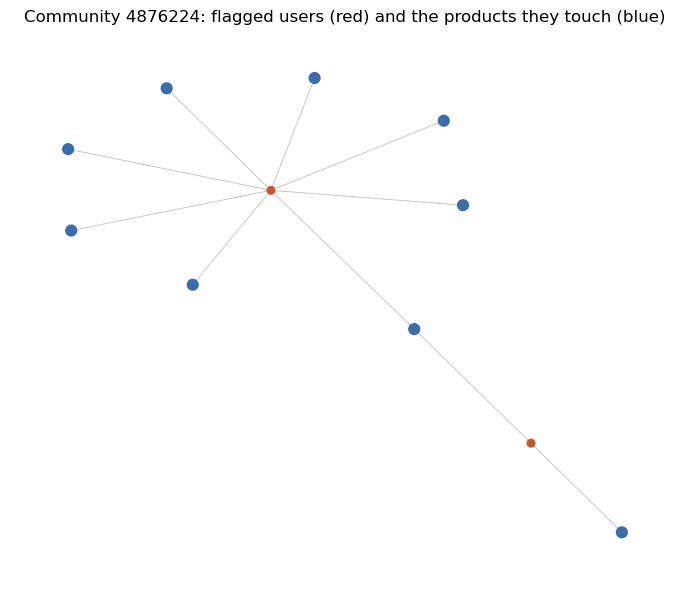

In [14]:
cand = comm[(comm.users >= 50) & (comm.users <= 5000)].sort_values("lift", ascending=False)
cid = int(cand.index[0]); metrics["visual_community"] = dict(id=cid, users=int(cand.iloc[0].users), flagged=int(cand.iloc[0].flagged), lift=float(cand.iloc[0].lift))
edges = q("""MATCH (u:User {community:$c, flagged:true})-[r:INTERACTED]->(p:Product) WITH u, p, sum(r.count) AS w
    ORDER BY w DESC LIMIT 120 RETURN u.userId AS u, p.productId AS p, p.brand AS brand, w""", c=cid)
G = nx.Graph()
for e in edges:
    G.add_node(("u", e["u"]), kind="user"); G.add_node(("p", e["p"]), kind="product", brand=e["brand"]); G.add_edge(("u", e["u"]), ("p", e["p"]), w=e["w"])
pos = nx.spring_layout(G, seed=7, k=0.35)
col = ["#c4572d" if G.nodes[n]["kind"] == "user" else "#3b6ea8" for n in G]
size = [30 if G.nodes[n]["kind"] == "user" else 60 for n in G]
fig, ax = plt.subplots(figsize=(7, 6))
nx.draw_networkx_edges(G, pos, alpha=.25, width=.6, ax=ax); nx.draw_networkx_nodes(G, pos, node_color=col, node_size=size, ax=ax)
ax.set_title(f"Community {cid}: flagged users (red) and the products they touch (blue)"); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_6_3_suspicious_subgraph.png", dpi=160); plt.show()
metrics["visual_graph"] = dict(nodes=G.number_of_nodes(), edges=G.number_of_edges()); save()

In [15]:
q("CALL gds.graph.drop('full', false)"); q("CALL gds.graph.drop('buy', false)")
save(); driver.close()

Received notification from DBMS server: <GqlStatusObject gql_status='01N03', status_description='warn: procedure field deprecated. The field `schema` of procedure gds.graph.drop() is deprecated.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "CALL gds.graph.drop('full', false)"


Received notification from DBMS server: <GqlStatusObject gql_status='01N03', status_description='warn: procedure field deprecated. The field `schema` of procedure gds.graph.drop() is deprecated.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "CALL gds.graph.drop('buy', false)"
